In [70]:
import pandas as pd
import numpy as np
import seaborn as sns

import matplotlib.pyplot as plt
import matplotlib.mlab as mlab
import matplotlib
plt.style.use('ggplot')
from matplotlib.pyplot import figure

%matplotlib inline
matplotlib.rcParams['figure.figsize'] = (12,8)

pd.options.mode.chained_assignment = None

C:\Users\sarat\AppData\Local\Temp\ipykernel_15628\3920158531.py:14: Pandas4Warning: The 'mode.chained_assignment' option is deprecated. It has had no effect since pandas 3.0, which removed the SettingWithCopyWarning it controlled. Chained assignment now emits a ChainedAssignmentError warning instead; use warnings.filterwarnings with category=ChainedAssignmentError to silence or escalate it. This option will be removed in pandas 4.0.
  pd.options.mode.chained_assignment = None


In [71]:
# Columns
# votes - how many votes from IMDb users,
# score - votes score

In [72]:
# load data
# source: https://www.kaggle.com/datasets/danielgrijalvas/movies, IMDb
df = pd.read_csv(r'movies.csv')

In [73]:
df.head(1)

,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime
0,The Shining,R,Drama,1980,"June 13, 1980 (United States)",8.4,927000.0,Stanley Kubrick,Stephen King,Jack Nicholson,United Kingdom,19000000.0,46998772.0,Warner Bros.,146.0


In [74]:
# display scrollable
# from IPython.display import HTML
# HTML(f'<div style="max-height:400px; overflow:auto">{df.to_html()}</div>')

In [75]:
# check dtype and missing
# pd.DataFrame({
#     'dtype': df.dtypes,
#     'missing': (df.isnull().mean() * 100).round().astype(int).astype(str) + '%'
# }).T


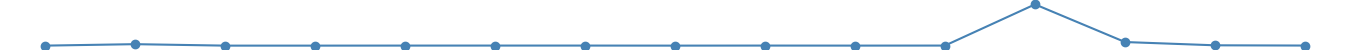

In [76]:
# check dtype and missing
import base64
from io import BytesIO
from IPython.display import HTML

pct = df.isnull().mean() * 100
n = len(pct)
colw = 90  # px per column

# chart exactly n * colw pixels wide, one point centered per column
fig = plt.figure(figsize=(n * colw / 100, 0.5), dpi=100)
ax = fig.add_axes([0, 0, 1, 1])
ax.plot(range(n), pct.values, marker='o', color='steelblue')
ax.set_xlim(-0.5, n - 0.5)
ax.set_ylim(-3, pct.max() + 3)
ax.axis('off')
buf = BytesIO()
fig.savefig(buf, format='png', transparent=True)
plt.close(fig)
img = base64.b64encode(buf.getvalue()).decode()

cell = f'style="width:{colw}px; padding:0; text-align:center"'
first = 'style="width:110px; padding:0; text-align:right"'

html = '<table style="table-layout:fixed; border-collapse:collapse">'
html += f'<tr><th {first}></th>' + ''.join(f'<th {cell}>{c}</th>' for c in pct.index) + '</tr>'
html += f'<tr><td {first}>dtype</td>' + ''.join(f'<td {cell}>{df[c].dtype}</td>' for c in pct.index) + '</tr>'
html += f'<tr><td {first}>missing</td>' + ''.join(f'<td {cell}>{p:.0f}%</td>' for p in pct) + '</tr>'
html += f'<tr><td {first}></td><td colspan="{n}" style="padding:0"><img src="data:image/png;base64,{img}" style="width:{n * colw}px; display:block"></td></tr>'
html += '</table>'

HTML(html)

In [77]:
# year and released column dont match so I will make new column year from released
df['year'] = df['released'].str.extract(r'(\d{4})')[0].astype('Int64')

In [78]:
# sort by gross ticket sales
# revenue = gross ticket sales - theatre cost, usualy half
# look at top 10 but dont permanently change df
df.sort_values(by='gross', ascending=False).head(2)

,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime
5445,Avatar,PG-13,Action,2009,"December 18, 2009 (United States)",7.8,1100000.0,James Cameron,James Cameron,Sam Worthington,United States,237000000.0,2.847246e+09,Twentieth Century Fox,162.0
7445,Avengers: Endgame,PG-13,Action,2019,"April 26, 2019 (United States)",8.4,903000.0,Anthony Russo,Christopher Markus,Robert Downey Jr.,United States,356000000.0,2.797501e+09,Marvel Studios,181.0


In [79]:
# check duplicates %
round(df.duplicated().mean() * 100, 2)

np.float64(0.0)

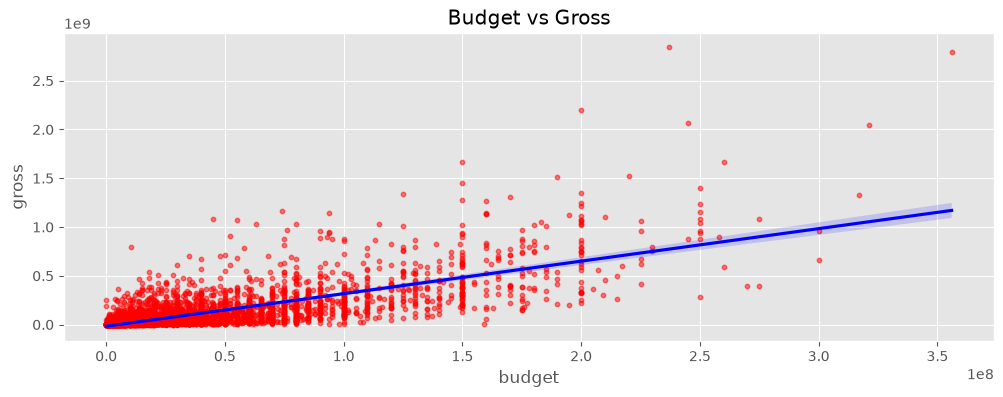

In [80]:
# positive correlation
# Scatter plot and lr with budget vs gross
# Plot budget vs gross using seaborn
# add linear regression line
# 1e8 = × 100,000,000, so 3.5 on budget = 350 million
plt.figure(figsize=(12, 4))
sns.regplot(x='budget', y='gross', data=df,
            scatter_kws={'color': 'red', 's': 10, 'alpha': 0.5},
            line_kws={'color': 'blue'})
plt.title('Budget vs Gross')
plt.show()

In [81]:
# correlation
# correlation pearson, other options kendall or spearman
# pearson is for normal data with few outliers, spearman skewd outliers, kendal for small samples
df.corr(numeric_only=True)

,year,score,votes,budget,gross,runtime
year,1.000000,0.105994,0.218429,0.321918,0.250514,0.120636
score,0.105994,1.000000,0.409182,0.076254,0.186258,0.399451
votes,0.218429,0.409182,1.000000,0.442429,0.630757,0.309212
budget,0.321918,0.076254,0.442429,1.000000,0.740395,0.320447
gross,0.250514,0.186258,0.630757,0.740395,1.000000,0.245216
runtime,0.120636,0.399451,0.309212,0.320447,0.245216,1.000000


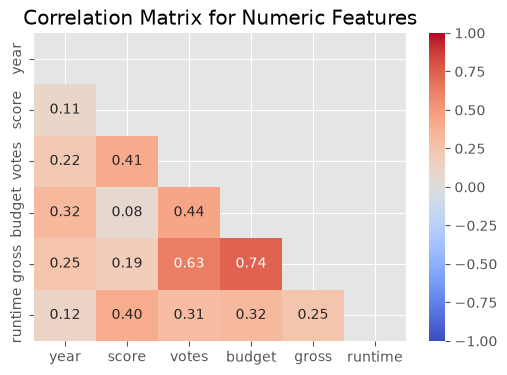

In [89]:
# correlation heatmap
# hide 1s diagonal
corr = df.corr(numeric_only=True)
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(6, 4))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix for Numeric Features')
plt.show()

In [83]:
# results
# budget and gross 0.74 strong: bigger budget bigger gross
# votes and gross 0.63: popular movies tend to earn more
# score vs gross 0.19 and budget 0.08: well rated movies don't necessarily earn more or cost more
# score and runtime 0.40 moderate: longer movies tend to get higher ratings
# year weak positive with budget and gross: possibly inflation, values are not adjusted

In [ ]:
# nunique companies
df['company'].nunique()
# make ai api map same studios to make a new column company group

2385

In [87]:
# new column company group map
company_map = {
    'Twentieth Century Fox': '20th Century Studios',
    '21st Century Films': '21st Century Film Corporation',
    '4 Kids Entertainment': '4Kids Entertainment',
    'ACCENT Films': 'Accent Films',
    'Accent Films B.V.': 'Accent Films',
    'Abandon Pictures': 'Abandon Entertainment',
    'Alive Enterprises': 'Alive Films',
    'Alliance Atlantis Communications': 'Alliance Atlantis',
    'Alliance Atlantis Motion Picture Production': 'Alliance Atlantis',
    'Alliance Films Corporation': 'Alliance Films',
    'American Playhouse Theatrical Films': 'American Playhouse',
    'Annapurna Productions': 'Annapurna Pictures',
    'Arnold Kopelson Productions': 'Kopelson Entertainment',
    'La Sept-Arte': 'Arte France Cinéma',
    'Atlantic': 'Atlantic Entertainment Group',
    'Avi Arad & Associates': 'Avi Arad Productions',
    'AVCO Embassy Pictures': 'Embassy Pictures',
    'Embassy International Pictures': 'Embassy Pictures',
    'Bakshi Animation': 'Bakshi Productions',
    'BET Films': 'BET',
    'BET Pictures': 'BET',
    'Black Entertainment Television (BET)': 'BET',
    'British Broadcasting Corporation (BBC)': 'BBC',
    'British Broadcasting Corporation (BBC) Television': 'BBC',
    'British Screen Finance Ltd.': 'British Screen',
    'British Screen Productions': 'British Screen',
    'Brownstone Entertainment (II)': 'Brownstone Productions',
    'Brownstone Productions (II)': 'Brownstone Productions',
    'Cannon Entertainment': 'Cannon Group',
    'Cannon Films': 'Cannon Group',
    'Cannon Films Inc.': 'Cannon Group',
    'Cannon International': 'Cannon Group',
    'Cannon Pictures': 'Cannon Group',
    'Cannon Screen Entertainment': 'Cannon Group',
    'The Cannon Group': 'Cannon Group',
    'Capella Films': 'Capella International',
    'Carolco Entertainment': 'Carolco Pictures',
    'Carolco International N.V.': 'Carolco Pictures',
    'Cecchi Gori Europa N.V.': 'Cecchi Gori Group',
    'Cecchi Gori Group Tiger Cinematografica': 'Cecchi Gori Group',
    'Cecchi Gori Pictures': 'Cecchi Gori Group',
    'Channel Four Film': 'Film4',
    'Channel Four Films': 'Film4',
    'Film 4': 'Film4',
    'Film Four International': 'Film4',
    'FilmFour': 'Film4',
    'Cinecom Entertainment Group': 'Cinecom',
    'Cinecom Pictures': 'Cinecom',
    'Cinema Group Ventures': 'Cinema Group',
    'Columbia Films': 'Columbia Pictures',
    'Columbia Pictures Industries': 'Columbia Pictures',
    'Concorde Pictures': 'Concorde-New Horizons',
    'Daiei Eiga': 'Daiei',
    'Daiei Studios': 'Daiei',
    'Delphi II Productions': 'Delphi Productions',
    'Delphi III Productions': 'Delphi Productions',
    'Delphi IV Productions': 'Delphi Productions',
    'Delphi V Productions': 'Delphi Productions',
    'Dino de Laurentiis Communications': 'Dino De Laurentiis Company',
    'DreamWorks': 'DreamWorks Pictures',
    'Dreamworks Pictures': 'DreamWorks Pictures',
    'Dune Entertainment III': 'Dune Entertainment',
    'Edward R. Pressman Productions': 'Pressman Productions',
    'Pressman Film': 'Pressman Productions',
    'Egoli Tossell KLK': 'Egoli Tossell',
    'Egoli Tossell Pictures': 'Egoli Tossell',
    'erbp': 'ERBP',
    'Fidélité Productions': 'Fidélité Films',
    'Filmax Entertainment': 'Filmax',
    'Filmax Group': 'Filmax',
    'Filmax International': 'Filmax',
    'FM Entertainment International N.V.': 'FM Entertainment',
    'Gaumont International': 'Gaumont',
    'The Geffen Company': 'Geffen Pictures',
    'Goldcrest Films International': 'Goldcrest Films',
    'Goldcrest Pictures': 'Goldcrest Films',
    'The Guber-Peters Company': 'Guber-Peters Company',
    'HBO Pictures': 'HBO Films',
    'Home Box Office (HBO)': 'HBO Films',
    'Heron Productions': 'Heron Communications',
    'Huayi Brothers Media': 'Huayi Brothers',
    'Huayi Brothers Pictures': 'Huayi Brothers',
    'IMF Internationale Medien und Film GmbH & Co. 2. Produktions KG': 'IMF Internationale Medien und Film',
    'IMF Internationale Medien und Film GmbH & Co. Produktions KG': 'IMF Internationale Medien und Film',
    'Imagine Films Entertainment': 'Imagine Entertainment',
    'Imperial Entertainment Corporation': 'Imperial Entertainment',
    'In-Gear Film Production': 'In-Gear Film',
    'Intermedia': 'Intermedia Films',
    'ITC Films': 'ITC',
    'Incorporated Television Company (ITC)': 'ITC',
    'J & M': 'J&M Entertainment',
    'Lantana Productions': 'Lantana',
    'Largo International N.V.': 'Largo Entertainment',
    'Leeds/Ben-Ami Productions': 'Ben-Ami/Leeds Productions',
    'Le Studio Canal+': 'StudioCanal',
    'Lions Gate Entertainment': 'Lionsgate',
    'Lions Gate Films': 'Lionsgate',
    'Lorimar Film Entertainment': 'Lorimar',
    'Lorimar Film Partners': 'Lorimar',
    'Lorimar Motion Pictures': 'Lorimar',
    'Lorimar Productions': 'Lorimar',
    'Lumiere Pictures': 'Lumière Pictures',
    'Malpaso Productions': 'Malpaso',
    'The Malpaso Company': 'Malpaso',
    'Mandalay Entertainment': 'Mandalay',
    'Mandalay Pictures': 'Mandalay',
    'Mandalay Vision': 'Mandalay',
    'Marvel Enterprises': 'Marvel Entertainment',
    'Material': 'Material Pictures',
    'Millenium': 'Millennium Media',
    'Millennium Films': 'Millennium Media',
    'The Mount Company (II)': 'The Mount Company',
    'NBC Film': 'NBC',
    'NBC Productions': 'NBC',
    'National Broadcasting Company (NBC)': 'NBC',
    'New Century Entertainment Corporation': 'New Century Entertainment',
    'New Visions': 'New Visions Pictures',
    'New World Entertainment Films': 'New World Pictures',
    'Nordisk Film / SPRING': 'Nordisk Film',
    'Nordisk Film Production Sverige AB': 'Nordisk Film',
    'Open Road Films (II)': 'Open Road Films',
    'Opera Film (II)': 'Opera Film',
    'Opera Film Produzione': 'Opera Film',
    'Pathé Pictures International': 'Pathé',
    'Penta Entertainment': 'Penta',
    'Penta Films': 'Penta',
    'Penta Pictures': 'Penta',
    'Polygram Filmed Entertainment': 'PolyGram Filmed Entertainment',
    'PolyGram Pictures': 'PolyGram Filmed Entertainment',
    'Polygram Pictures': 'PolyGram Filmed Entertainment',
    'Portman Entertainment Group': 'Portman Entertainment',
    'Portman Productions': 'Portman Entertainment',
    'Price': 'Price Entertainment',
    'Process Film': 'Process Media',
    'Raffaella De Laurentiis Productions': 'Raffaella Productions',
    'Rastar Films': 'Rastar',
    'Rastar Pictures': 'Rastar',
    'Rastar Productions': 'Rastar',
    'River Road Productions': 'River Road Entertainment',
    'Rogue': 'Rogue Pictures',
    'Sahamongkolfilm Co.': 'Sahamongkol Film International',
    'Senator Entertainment Co': 'Senator Entertainment',
    'Senator Film Produktion': 'Senator Entertainment',
    'Silver Screen Partners II': 'Silver Screen Partners',
    'Silver Screen Partners III': 'Silver Screen Partners',
    'Silver Screen Partners IV': 'Silver Screen Partners',
    'Six Entertainment Company': 'Six Entertainment',
    'STX Films': 'STX Entertainment',
    'Tartan Productions': 'Tartan Films',
    'TMS Pictures': 'TMS Entertainment',
    'Tri Star Productions': 'TriStar Pictures',
    'United Artists Film Corporation': 'United Artists',
    'United Artists Pictures': 'United Artists',
    'Universal City Studios': 'Universal Pictures',
    'The Vista Organisation': 'Vista Organization',
    'Walt Disney Productions': 'Walt Disney Pictures',
    'Warner Bros.': 'Warner Bros. Pictures',
    'Warner Independent Pictures (WIP)': 'Warner Independent Pictures',
    'WIP': 'Warner Independent Pictures',
    'Yari Film Group (YFG)': 'Yari Film Group',
    'Yari Film Group Releasing': 'Yari Film Group',
}

df['company_group'] = df['company'].replace(company_map)

In [88]:
# add company group column
df['company_group'] = df['company'].map(company_map).fillna(df['company'])

In [92]:
# add number column for each non number column for corelation
for col in df.select_dtypes(exclude='number').columns:
    df[col + '_num'] = df[col].astype('category').cat.codes

In [93]:
df.corr(numeric_only=True)

,year,score,votes,budget,gross,runtime,name_num,rating_num,genre_num,released_num,director_num,writer_num,star_num,country_num,company_num,company_group_num
year,1.000000,0.105994,0.218429,0.321918,0.250514,0.120636,0.010699,0.006741,-0.077911,-0.004644,-0.020422,-0.008611,-0.027611,-0.080844,-0.015171,-0.007133
score,0.105994,1.000000,0.409182,0.076254,0.186258,0.399451,0.017097,-0.001314,0.027965,0.042788,0.009559,0.019416,-0.001609,-0.133348,0.001030,0.020372
votes,0.218429,0.409182,1.000000,0.442429,0.630757,0.309212,0.013088,0.033225,-0.145307,0.016097,0.000260,0.000892,-0.019282,0.073625,0.133204,0.093457
budget,0.321918,0.076254,0.442429,1.000000,0.740395,0.320447,0.023970,-0.176002,-0.356564,0.014683,-0.012272,-0.039451,-0.019589,0.054063,0.173214,0.114023
gross,0.250514,0.186258,0.630757,0.740395,1.000000,0.245216,0.005533,-0.107339,-0.235650,0.001659,-0.014441,-0.023519,-0.002717,0.092129,0.154840,0.098632
runtime,0.120636,0.399451,0.309212,0.320447,0.245216,1.000000,0.010392,0.062145,-0.052711,0.000868,0.017624,-0.003511,0.010174,-0.078412,0.034402,0.030262
name_num,0.010699,0.017097,0.013088,0.023970,0.005533,0.010392,1.000000,-0.008069,0.016355,-0.011311,0.009079,0.009081,0.006472,-0.010737,0.009211,0.006025
rating_num,0.006741,-0.001314,0.033225,-0.176002,-0.107339,0.062145,-0.008069,1.000000,0.072423,0.016613,0.019483,-0.005921,0.013405,0.081244,-0.032943,-0.029459
genre_num,-0.077911,0.027965,-0.145307,-0.356564,-0.235650,-0.052711,0.016355,0.072423,1.000000,0.029822,-0.015258,0.006567,-0.005477,-0.037615,-0.071067,-0.029216
released_num,-0.004644,0.042788,0.016097,0.014683,0.001659,0.000868,-0.011311,0.016613,0.029822,1.000000,-0.001478,-0.002404,0.015777,-0.020427,-0.010474,0.002545


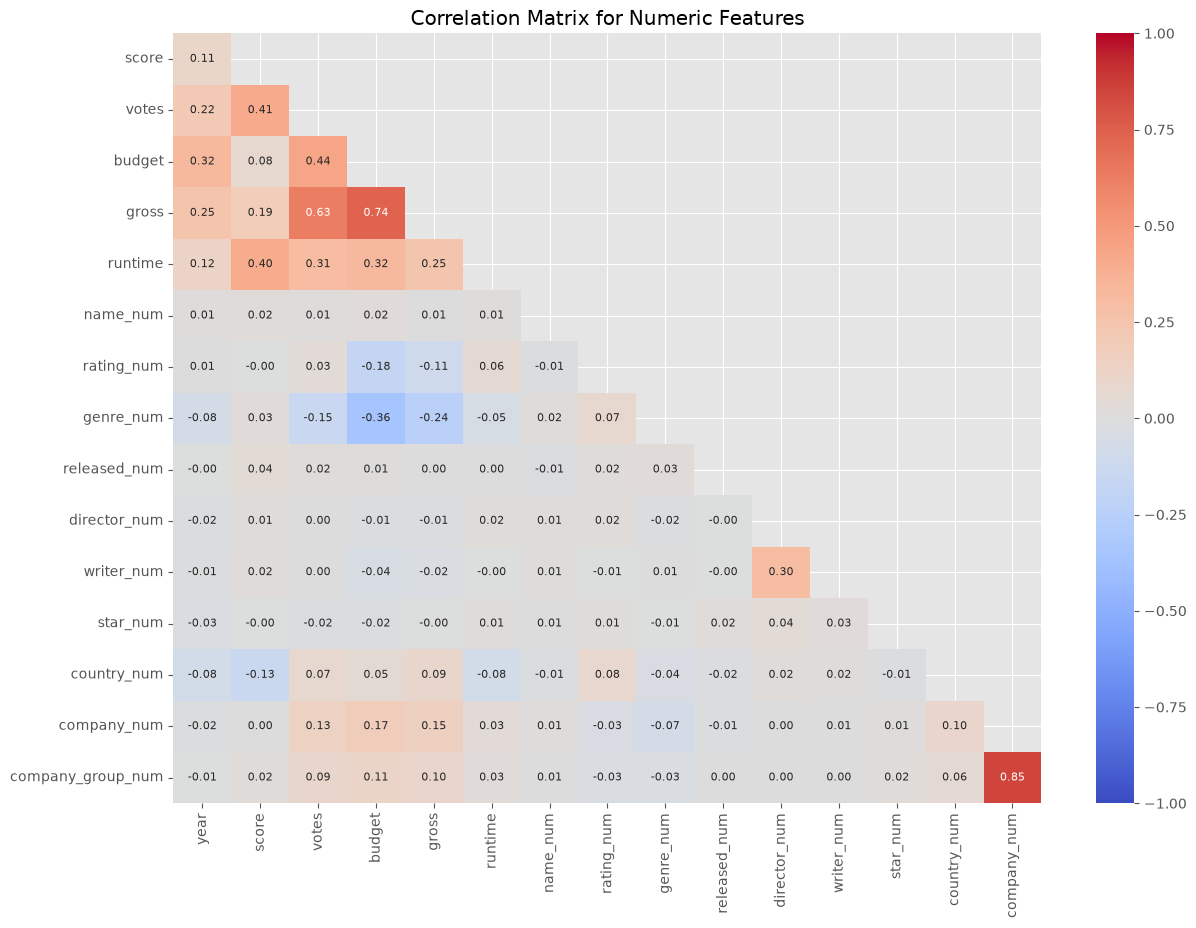

In [94]:
# correlation heatmap
# hide 1s diagonal
corr = df.corr(numeric_only=True)
mask = np.triu(np.ones_like(corr, dtype=bool))

# drop empty first row and last column
corr = corr.iloc[1:, :-1]
mask = mask[1:, :-1]

plt.figure(figsize=(14, 10))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, annot_kws={'size': 8})
plt.title('Correlation Matrix for Numeric Features')
plt.show()

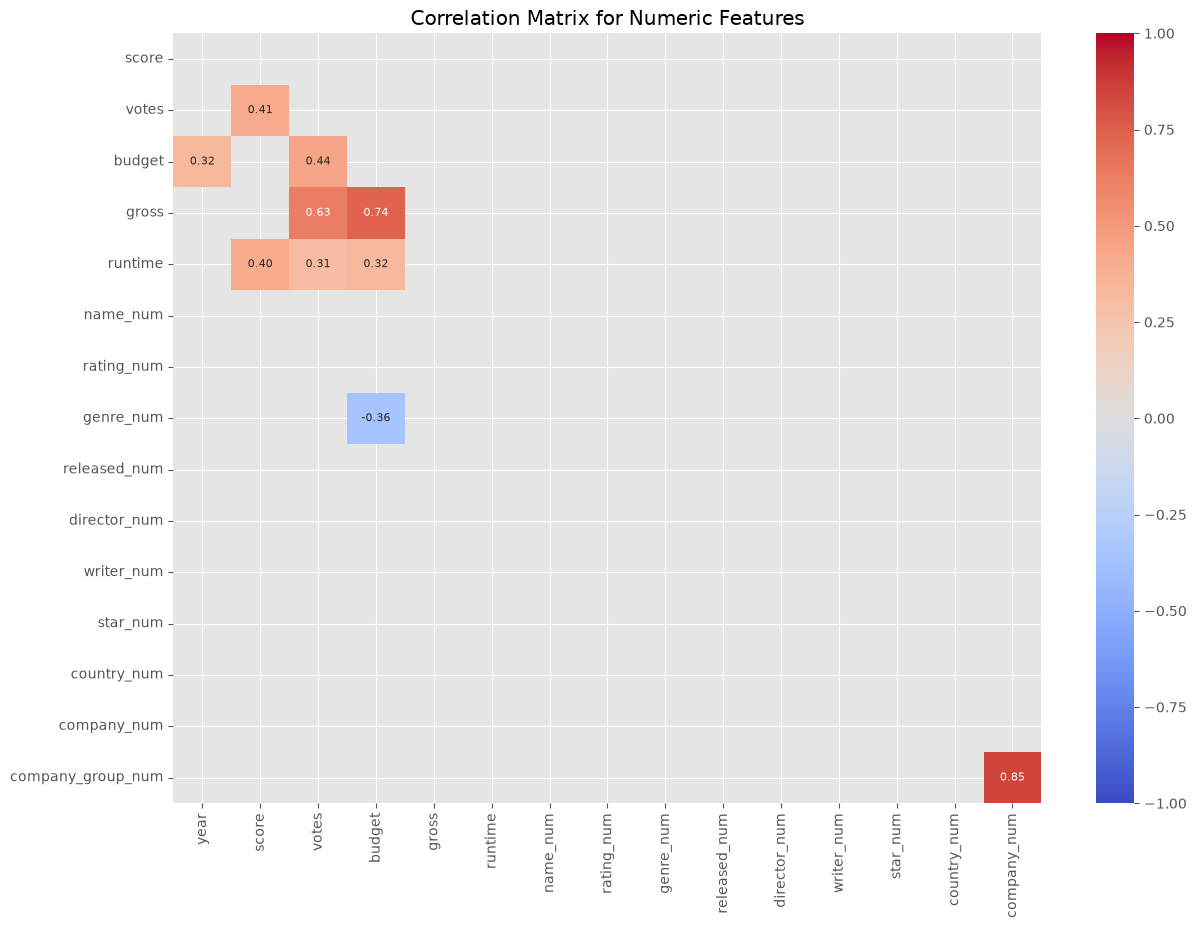

In [ ]:
# correlation heatmap
# only correlations over 0.3, hide diagonal
corr = df.drop(columns='company_num').corr(numeric_only=True)
mask = np.triu(np.ones_like(corr, dtype=bool)) | (corr <= 0.3).values

# drop rows and columns with nothing to show
keep_rows = ~mask.all(axis=1)
keep_cols = ~mask.all(axis=0)
corr = corr.loc[keep_rows, keep_cols]
mask = mask[keep_rows][:, keep_cols]

plt.figure(figsize=(10, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, annot_kws={'size': 8})
plt.title('Correlations over 0.3')
plt.show()